# Level 3: fuzzy-logic prioritization, evaluation

Compares a CVSS baseline, the fuzzy prioritizer (CVSS, EPSS, exposure, criticality) and an
ablation without EPSS. Ground truth (proxy): membership in the CISA KEV catalog.
Reproduce: `uv run python -m fuzzy.build_dataset && uv run python -m fuzzy.evaluate`.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display
from scipy.stats import spearmanr

from fuzzy.fuzzy_engine import ABLATION_RULES, BASE_RULES, EXTRA_RULES, coverage_check, prioritize

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
df = pd.read_csv(ROOT / "data/eval/cves.csv")
metrics = json.loads((ROOT / "fuzzy/results/metrics.json").read_text())

## 1. Dataset

In [2]:
print(f"{len(df)} CVEs; KEV positives: {df.in_kev.sum()} ({df.in_kev.mean():.1%} base rate)")
display(df.groupby("source").agg(n=("cve_id", "count"), kev=("in_kev", "sum"),
                                 cvss_mean=("cvss", "mean"), epss_median=("epss", "median")))
print("attack vectors:", df.attack_vector.value_counts().to_dict())
print("exposure values:", df.exposure.value_counts().to_dict())
display(df.head())

510 CVEs; KEV positives: 15 (2.9% base rate)


,n,kev,cvss_mean,epss_median
source,,,,
lab,410,15,6.790976,0.012145
nvd_sample,100,0,7.072000,0.009455


attack vectors: {'NETWORK': 485, 'LOCAL': 23, 'PHYSICAL': 1, 'ADJACENT_NETWORK': 1}
exposure values: {8: 485, 2: 23, 1: 1, 5: 1}


,cve_id,source,cvss,attack_vector,epss,in_kev,exposure,criticality,cwes,asset
0,CVE-2006-20001,lab,7.5,NETWORK,0.03722,0,8,7,CWE-787,httpd 2.4.49
1,CVE-2009-2197,nvd_sample,4.3,NETWORK,0.01415,0,8,5,CWE-19,NaN
2,CVE-2013-0507,nvd_sample,8.1,NETWORK,0.01206,0,8,5,CWE-384,NaN
3,CVE-2015-1427,lab,9.8,NETWORK,0.99906,1,8,8,NaN,Elasticsearch 1.4.2
4,CVE-2015-5377,lab,9.8,NETWORK,0.14602,0,8,8,CWE-74,Elasticsearch 1.4.2


Exposure comes from the CVSS attack vector and criticality from a small lab table
(sample CVEs fixed at 5), so both are **assumptions**, not measurements.

## 2. Rule base and coverage

In [3]:
for flag in (True, False):
    rep = coverage_check(flag)
    name = "with EPSS" if flag else "ablation (no EPSS)"
    print(f"{name}: {rep['n_rules']} rules, {rep['combinations']} term combinations, "
          f"uncovered = {rep['n_uncovered']}")
print(f"\nFull rule base = {len(BASE_RULES)} proposal rules + {len(EXTRA_RULES)} added rules")
rules = pd.DataFrame([{"id": r["id"], "kind": "proposal" if r in BASE_RULES else "added",
                       "rule": r["text"], "justification": r["justification"] or ""}
                      for r in BASE_RULES + EXTRA_RULES])
pd.set_option("display.max_colwidth", 120)
display(rules)

with EPSS: 22 rules, 108 term combinations, uncovered = 0
ablation (no EPSS): 16 rules, 36 term combinations, uncovered = 0

Full rule base = 7 proposal rules + 15 added rules


,id,kind,rule,justification
0,R1,proposal,IF cvss is critical AND epss is high THEN priority is urgent,
1,R2,proposal,IF exposure is internet AND cvss is high THEN priority is high,
2,R3,proposal,IF criticality is high AND cvss is medium AND exposure is internet THEN priority is high,
3,R4,proposal,IF exposure is dmz AND epss is medium THEN priority is medium,
4,R5,proposal,IF epss is low AND exposure is internal THEN priority is low,
5,R6,proposal,IF cvss is low AND epss is low THEN priority is low,
6,R7,proposal,IF criticality is high AND epss is high THEN priority is urgent,
7,R8,added,IF cvss is critical AND exposure is internet THEN priority is urgent,A critical flaw on an internet-facing asset is urgent even before EPSS catches up.
8,R9,added,IF cvss is critical AND epss is medium THEN priority is high,Critical severity with moderate exploit probability stays high.
9,R10,added,IF cvss is critical AND epss is low THEN priority is medium,Critical severity but exploitation is unlikely: still worth scheduling.


In [4]:
display(pd.DataFrame([{"id": r["id"], "rule": r["text"], "justification": r["justification"]}
                      for r in ABLATION_RULES]))

,id,rule,justification
0,N1,IF cvss is critical AND criticality is high THEN priority is urgent,Proposal rules 1 and 7 without EPSS: critical flaw on a high-value asset.
1,N2,IF exposure is internet AND cvss is high THEN priority is high,"Proposal rule 2, unchanged (no EPSS in it)."
2,N3,IF criticality is high AND cvss is medium AND exposure is internet THEN priority is high,"Proposal rule 3, unchanged (no EPSS in it)."
3,N4,IF cvss is critical AND exposure is internet THEN priority is urgent,Critical and internet-facing is urgent.
4,N5,IF cvss is critical AND exposure is dmz THEN priority is high,Critical in the DMZ: high.
5,N6,IF cvss is critical AND exposure is internal THEN priority is high,"Critical but internal: high (impact is severe, reach is limited)."
6,N7,IF cvss is high AND exposure is dmz THEN priority is medium,High severity in the DMZ: medium.
7,N8,IF cvss is high AND exposure is internal THEN priority is medium,"High severity, internal only: medium."
8,N9,IF cvss is medium AND exposure is internet THEN priority is medium,Medium severity reachable from the internet: medium.
9,N10,IF cvss is medium AND exposure is dmz THEN priority is medium,Proposal rule 4 without EPSS: medium severity in the DMZ.


## 3. Metrics (read from fuzzy/results/metrics.json)

In [5]:
names = {"cvss": "CVSS baseline", "fuzzy": "Fuzzy (with EPSS)", "fuzzy_no_epss": "Fuzzy (no EPSS)"}
table = pd.DataFrame(metrics["methods"]).T.rename(index=names)
det = table[["precision_at_10", "recall_at_20", "f1_at_20", "hits_top10", "hits_top20",
             "distinct_scores", "latency_ms"]]
print("Deterministic (cve_id tie-break):")
display(det.round({"precision_at_10": 2, "recall_at_20": 2, "f1_at_20": 2, "latency_ms": 5}))
exp = pd.DataFrame({names[m]: v["expected_random_ties"] for m, v in metrics["methods"].items()}).T
print("Expected under uniformly random tie-breaking (exact, hypergeometric):")
display(exp.round(3))
print(metrics["definitions"])

Deterministic (cve_id tie-break):


,precision_at_10,recall_at_20,f1_at_20,hits_top10,hits_top20,distinct_scores,latency_ms
CVSS baseline,0.5,0.4,0.342857,5,6,43,0.000021
Fuzzy (with EPSS),0.8,0.8,0.685714,8,12,95,0.680608
Fuzzy (no EPSS),0.5,0.4,0.342857,5,6,29,0.54305


Expected under uniformly random tie-breaking (exact, hypergeometric):


,precision_at_10,recall_at_20,f1_at_20
CVSS baseline,0.204,0.272,0.233
Fuzzy (with EPSS),0.833,0.800,0.686
Fuzzy (no EPSS),0.204,0.272,0.233


{'precision_at_10': 'KEV hits in top 10 / 10', 'recall_at_20': 'KEV hits in top 20 / KEV positives', 'f1_at_20': 'harmonic mean of precision@20 and recall@20', 'ties': 'deterministic numbers: score descending, then cve_id ascending', 'expected_random_ties': 'exact expectation under uniformly random tie-breaking (hypergeometric mean within the tied group straddling the cutoff; F1@20 = 2*hits/(20+positives) is linear in hits)'}


## 4. Charts

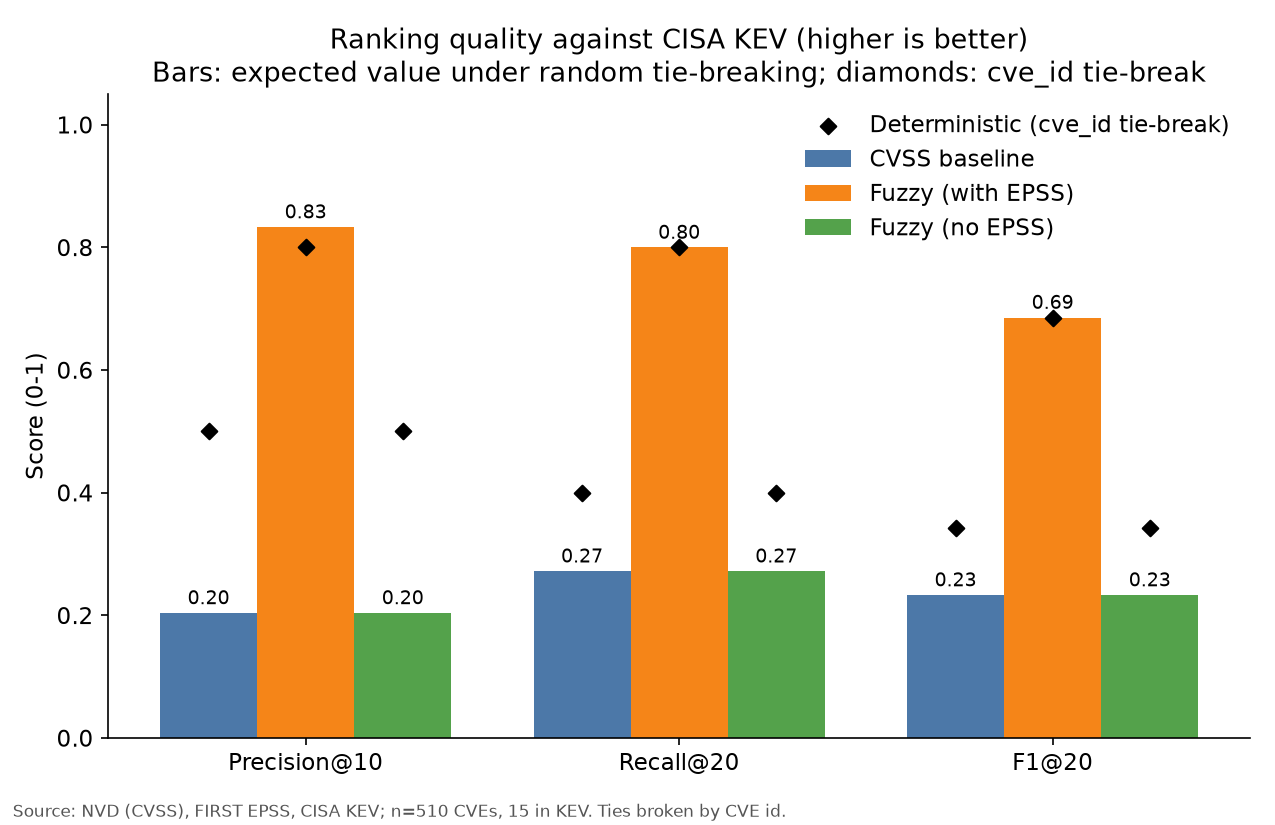

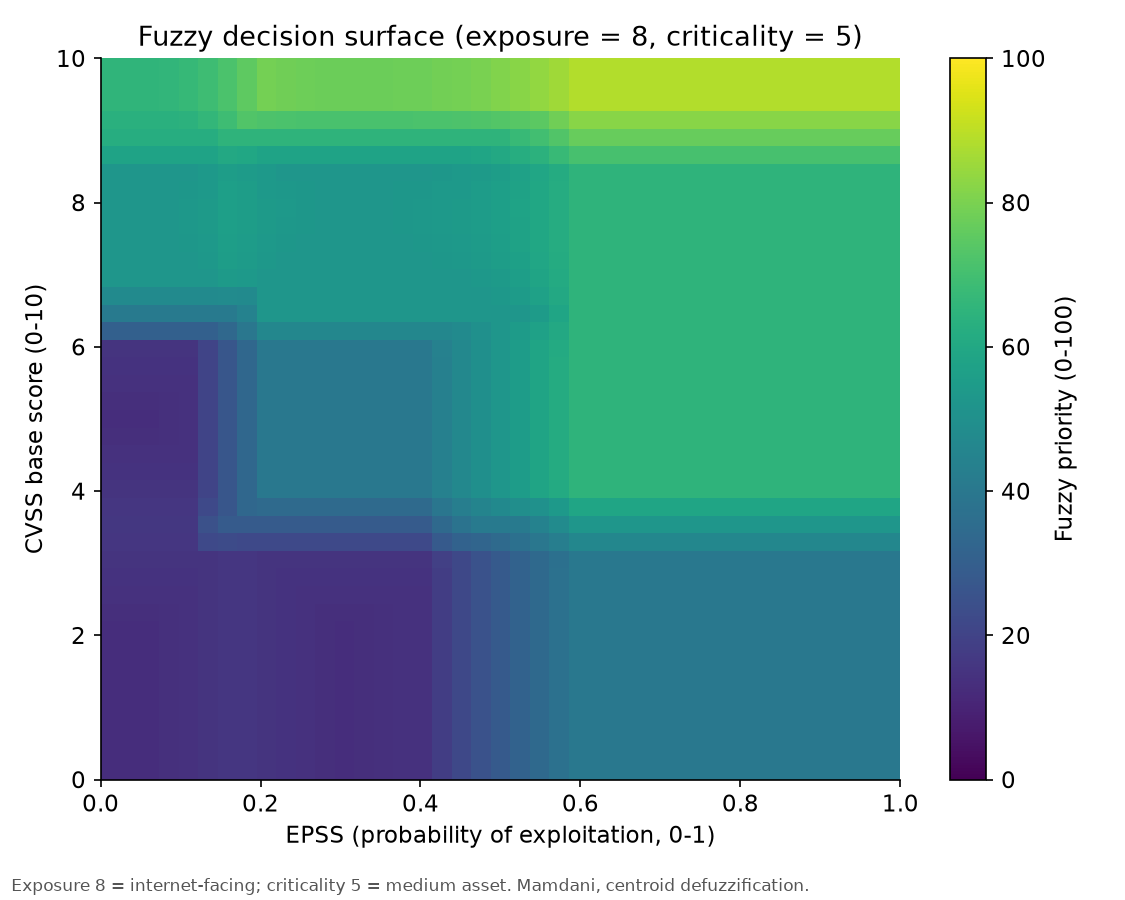

In [6]:
display(Image(ROOT / "docs/figures/metrics_comparison.png"))
display(Image(ROOT / "docs/figures/decision_surface.png"))

## 5. Evidence for the analysis

In [7]:
print("Spearman(EPSS, KEV) =", round(spearmanr(df.epss, df.in_kev)[0], 3))
print("Spearman(CVSS, KEV) =", round(spearmanr(df.cvss, df.in_kev)[0], 3))
print("mean EPSS  KEV:", round(df[df.in_kev == 1].epss.mean(), 3),
      " non-KEV:", round(df[df.in_kev == 0].epss.mean(), 3))
print("CVSS >= 9:", int((df.cvss >= 9).sum()), "CVEs, of which in KEV:",
      int(df[df.cvss >= 9].in_kev.sum()))
rk = pd.read_csv(ROOT / "fuzzy/results/rankings.csv")
top = rk[rk.method == "fuzzy"].head(20)
print("fuzzy top-20 score values:", sorted(top.score.unique(), reverse=True)[:5], "...")
print("CVEs tied at the top fuzzy score:", int((rk[rk.method == "fuzzy"].score
      == top.score.max()).sum()))
print("monotonicity probe (exposure 8, criticality 5):")
for c in (4, 6, 8, 9.8):
    print("  cvss", c, "->", prioritize(c, 0.9, 8, 5)["priority"])

Spearman(EPSS, KEV) = 0.291
Spearman(CVSS, KEV) = 0.231
mean EPSS  KEV: 0.982  non-KEV: 0.069
CVSS >= 9: 68 CVEs, of which in KEV: 11
fuzzy top-20 score values: [np.float64(88.33), np.float64(81.15), np.float64(79.62), np.float64(78.99), np.float64(78.81)] ...
CVEs tied at the top fuzzy score: 12
monotonicity probe (exposure 8, criticality 5):
  cvss 4 -> 65.0
  cvss 6 -> 65.0
  cvss 8 -> 65.0
  cvss 9.8 -> 88.33


## 6. Critical analysis and limitations

**What the numbers say.** With the deterministic cve_id tie-break, the fuzzy prioritizer with EPSS reaches Precision@10 = 0.80,
Recall@20 = 0.80 and F1@20 = 0.69, against 0.50, 0.40 and 0.34 for the CVSS baseline (15 KEV positives
among 510 CVEs, a 2.9% base rate). Because ties are heavy, the notebook also reports the exact expected
value under uniformly random tie-breaking: 0.833, 0.800, 0.686 for fuzzy with EPSS and 0.204, 0.272,
0.233 for the baseline. The fuzzy numbers are stable (the ties at the top are mostly KEV CVEs), while the
baseline's deterministic 0.50 / 0.40 / 0.34 was lucky: its expected performance is much lower, so the
gap to the baseline is larger than the deterministic table suggests. The fuzzy variant without EPSS is **identical** to the baseline on
these metrics, deterministic (0.50, 0.40, 0.34) and expected (0.204, 0.272, 0.233). So, on this dataset, the whole improvement comes from the EPSS
input; exposure and criticality as encoded here add nothing measurable.

**EPSS and KEV are correlated (evaluation bias).** KEV CVEs have mean EPSS 0.98 against 0.07
for the others, and EPSS is trained on exploitation evidence that overlaps what KEV records. The
ablation quantifies this: removing EPSS removes the gain. The result therefore shows that EPSS
is a strong exploitation signal, not that the fuzzy rules beat CVSS on their own. A fair
reading is that fuzzy logic is a transparent way to fuse EPSS with CVSS and context.

**Exposure and criticality are weak by construction.** 485 of 510 CVEs have attack vector
NETWORK, so exposure is almost constant (8). Criticality is 5 for every sample CVE and 3 to 9
for lab CVEs, so it is confounded with `source`: all 15 KEV CVEs are lab CVEs (the lab was built
from known-exploited software). These inputs were assigned by hand and were not validated.

**Small sample and ties.** With 15 positives, each extra hit moves Recall@20 by 0.067 and the
metrics have wide uncertainty; no significance test is claimed. The fuzzy ranking has 12 CVEs
tied at the maximum score 88.33 (the saturation of the urgent term), so the order inside that
group, and therefore part of Precision@10, depends on the tie-break (cve_id ascending). CVSS has
many ties as well (43 distinct scores). The expected-value metrics above remove this dependence.

**Rule base revised after a first run.** After the first evaluation the decision surface showed
a drop in priority for CVSS around 8 versus 6.5 caused by one added rule (an internet and high
EPSS rule). It was removed and the results were regenerated (Recall@20 went from 0.73 to 0.80).
This is a form of tuning on the evaluation set and is disclosed here; the base rules from the
proposal were not changed.

**Non-monotonicity.** Centroid defuzzification is not monotonic: a stronger activation of a
medium or high rule can pull the centroid down when an urgent rule is already active. The tests
therefore only assert coarse monotonicity between well separated inputs.

**Other limitations.** Membership functions come from expert judgment, not data. KEV is a lagging
and incomplete proxy for risk (a CVE not in KEV is not necessarily harmless). The dataset (510
CVEs) is larger than the 200 targeted in the proposal because all 410 lab-linked CVEs were
kept (the lab-linked CVEs alone already exceed 200, and the proposal asks for all of them). Latency is dominated by Python and scikit-fuzzy calls (about 0.5 to 0.7 ms per CVE) and is
irrelevant for triage volumes, but it is orders of magnitude above reading a CVSS score.

**Future work.** Learn the membership functions (ANFIS), validate against analyst rankings, and
evaluate on a dataset where exposure and criticality actually vary.